# Difusión de calor en una dimensión espacial

La idea del ejercicio es apreciar como evoluciona la distribución de temperatura a lo largo del tiempo cuando se aplica una fuente de calor en el **borde izquierdo** de una placa. 

## Planteamiento 

Suponemos que tenemos una placa delgada metálica de longitud $L = 1.0m$ y grosor desprecialbe, de modo que el flujo de calor ocurre solo a lo largo del eje x. La temperatura en la barra cambia con el tiempo debido a la difusión del calor desde el borde izquierdo hacia el borde derecho. 

En el tiempo inicial $t=0$, toda la barra está a una temperatura uniforme de 0°C. A partir de ese momento, el **borde izquierdo** ($x=0$) se mantiene a una temperatura constante de 100°C, mientras que el **borde derecho** ($x=L$) permanece a 0°C.

El objetivo es simular la evolución temporal de la temperatura a lo largo de la barra con ayuda de la **ecuación de difusión de calor en 1D**. 

$$\frac{\partial T}{\partial t} = \alpha \frac{\partial^2 T}{\partial x^2}$$

donde:
- $T(x,t)$ es la temperatura en la posición x y tiempo t.
- $\alpha$ es la difusividad térmica del material en $\frac{m^2}{s}$

## Paso 1 Definir el dominio espacial y temporal

- Definir la longitud de la barra L y el número de puntos N en la malla espacial
- Calcular $dx = \frac{L}{N-1}$
- Define el número de pasos de tiempo Nt y el paso de tiempo dt respetando la condición de estabilidad para diferencias fínitas explícitas: 

$$dt \leq \frac{dx^2}{2\alpha}$$

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Paso 1 
L = 1
alph = 1e-4 #m^2/s
N = 100
dt = 0.01
tiempo = 1000
nt = int(tiempo/dt)
dx = L/(N-1)

print(f"Checamos condicion de estabilidad para diferencias finitas. Es cierta la condición: {dt <= dx**2/(2*alph)}")

Checamos condicion de estabilidad para diferencias finitas. Es cierta la condición: True


## Paso 2. Inicializar la temperatura

- Crear un arreglo de T de longitud N, inicializado con ceros
- Aplica la condición de frontera izquierda: $T[0] = 100$
- Aplica la condición de frontera derecha: $T[N-1] = 0$

In [8]:
# Creamos vector de ceros para la temperatura
T = np.zeros((nt,N))
print(f"El tamanio de la matriz para la temperatura en el tiempo: {np.shape(T)}")

# Aplicamos condicion de frontera izquierda
T[:,0] = 100
#Aplicamos condición de frontera derecha
# Esta planteada implicitamente a través de la generación de la matriz. 

print(T)

El tamanio de la matriz para la temperatura en el tiempo: (100000, 100)
[[100.   0.   0. ...   0.   0.   0.]
 [100.   0.   0. ...   0.   0.   0.]
 [100.   0.   0. ...   0.   0.   0.]
 ...
 [100.   0.   0. ...   0.   0.   0.]
 [100.   0.   0. ...   0.   0.   0.]
 [100.   0.   0. ...   0.   0.   0.]]


## Paso 3. Iterar en el tiempo

- Para cada paso de tiempo, actualizar el valor de temperatura en los puntos interiores usando diferencias finitas:

$$T^{n+1}_i = T^n_i + \alpha \frac{dt}{dx^2} (T^n_{i+1} - 2T^n_i +T^n_{i-1})$$

- Mantén fijas las condiciones de frontera

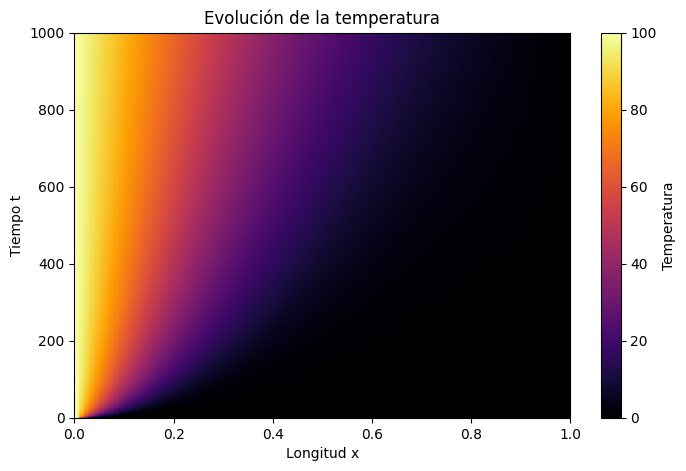

In [9]:
def diferencias_finitas(T,nt,N):

    for t in range(nt-1):
        for l in range(1, N-1):
            T[t+1,l] = T[t, l] + alph*(dt/dx**2) * (T[t, l + 1] - 2*T[t, l] + T[t, l-1])
        
        T[t + 1,0] = 100

    return T

plt.figure(figsize=(8, 5))
plt.imshow(diferencias_finitas(T, nt, N), aspect='auto', origin='lower', cmap='inferno',
           extent=[0, L, 0, tiempo])
plt.colorbar(label='Temperatura')
plt.xlabel('Longitud x')
plt.ylabel('Tiempo t')
plt.title('Evolución de la temperatura')
plt.show()



## Mejoras al código para visualización de resultados


Debido a que para las graficaciones se requieren realizar cambios a alfa y a las temperaturas, decidi hacer este proceso a través de una función que pueda ser más personalizable para aceptar diferenes parámetros. Para ello mi funcion va aceptar diferentes tamaños nt, N, asi como diversos valores para los parámetros de alfa y de frontera para hacerlo más modular. 

El tamanio de la matriz para la temperatura en el tiempo: (100001, 100)
Checamos condicion de estabilidad para diferencias finitas.
 Es cierta la condición para alfa0.0001 es : True
El tamanio de la matriz para la temperatura en el tiempo: (100001, 100)
Checamos condicion de estabilidad para diferencias finitas.
 Es cierta la condición para alfa0.0001 es : True
El tamanio de la matriz para la temperatura en el tiempo: (100001, 100)
Checamos condicion de estabilidad para diferencias finitas.
 Es cierta la condición para alfa0.0003 es : True
El tamanio de la matriz para la temperatura en el tiempo: (100001, 100)
Checamos condicion de estabilidad para diferencias finitas.
 Es cierta la condición para alfa0.0005 es : True
El tamanio de la matriz para la temperatura en el tiempo: (100001, 100)
Checamos condicion de estabilidad para diferencias finitas.
 Es cierta la condición para alfa0.0001 es : True
El tamanio de la matriz para la temperatura en el tiempo: (100001, 100)
Checamos condicion

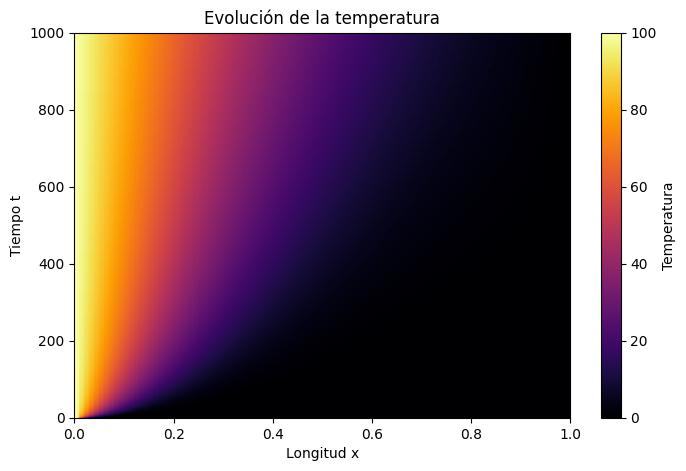

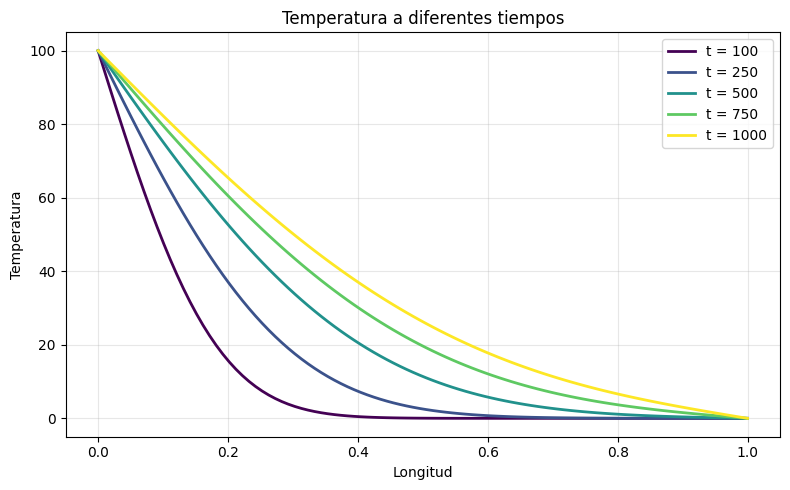

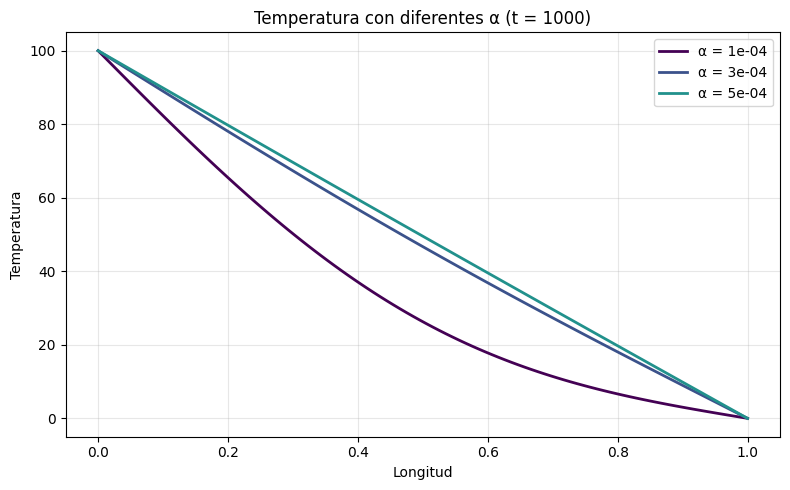

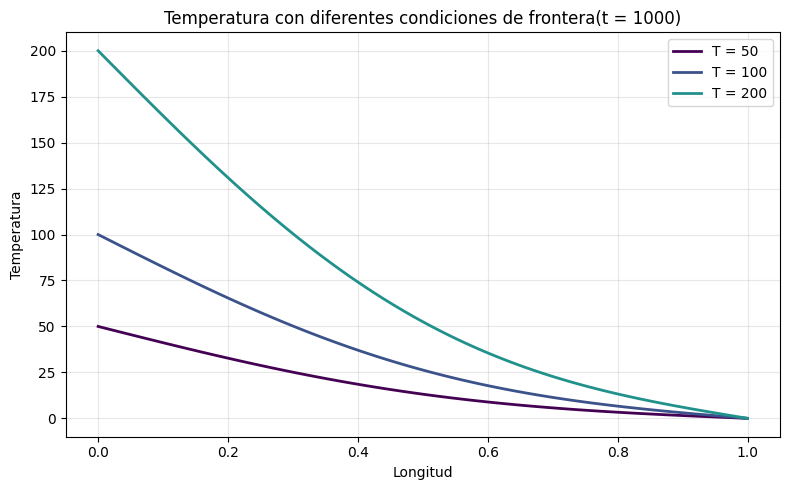

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Paso 1 Condiciones iniciales
L = 1
alph = 1e-4 #m^2/s
N = 100
dt = 0.01
Tiempos = [100, 250, 500, 750, 1000]
alpha = [1e-4, 3e-4,5e-4]
t_fronteras = [50, 100, 200]
tiempo = max(Tiempos)
nt = int(tiempo/dt) + 1
dx = L/(N-1)
x = np.linspace(0, L, N)

# Funcion completa con paso 2 y 3
def diferencias_finitas(nt,N, alfa = 1e-4, frontera = 100):
    # Creamos vector de ceros para la temperatura
    T = np.zeros((nt,N))
    print(f"El tamanio de la matriz para la temperatura en el tiempo: {np.shape(T)}")
    print(f"Checamos condicion de estabilidad para diferencias finitas.\n Es cierta la condición para alfa{alfa} es : {dt <= dx**2/(2*alfa)}")

    # Aplicamos condicion de frontera izquierda
    T[:,0] = frontera
    #Aplicamos condición de frontera derecha
    # Esta planteada implicitamente a través de la generación de la matriz. 
    # print(T)

    for t in range(nt-1):
        for l in range(1, N-1):
            T[t+1,l] = T[t, l] + alfa*(dt/dx**2) * (T[t, l + 1] - 2*T[t, l] + T[t, l-1])
        
        T[t + 1,0] = frontera

    return T

# Calculamos para el tiempo maximo (asi lo defini arriba)
T = diferencias_finitas(nt, N)

# Creamos la simulacion para diferentes alfas
resultados_alfa = []
for al in alpha:
    resultados_alfa.append(diferencias_finitas(nt,N,alfa=al))

# Creamos simulacion para diferentes condiciones de frontera
resultados_frontera = []
for tf in t_fronteras:
    resultados_frontera.append(diferencias_finitas(nt,N,frontera=tf))

# Mapa de calor para la evolucion temporal de la transferencia del calor
plt.figure(figsize=(8, 5))
plt.imshow(T, aspect='auto', origin='lower', cmap='inferno',
           extent=[0, L, 0, tiempo])
plt.colorbar(label='Temperatura')
plt.xlabel('Longitud x')
plt.ylabel('Tiempo t')
plt.title('Evolución de la temperatura')
plt.show()

# Gráfica de temperatura para diferentes tiempos
plt.figure(figsize=(8, 5))
colores = plt.get_cmap("viridis")(np.linspace(0, 1, len(Tiempos)))
for tp, c in zip(Tiempos, colores):
    idx = int(int(tp / dt))
    plt.plot(x, T[idx], color=c, lw=2, label=f"t = {tp}")
plt.xlabel("Longitud")
plt.ylabel("Temperatura")
plt.title("Temperatura a diferentes tiempos")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Grafica para diferentes alfas 
idx = int(tiempo/dt)
plt.figure(figsize=(8, 5))
for al, T_al, c in zip(alpha, resultados_alfa, colores):
    plt.plot(x, T_al[idx], color=c, lw=2, label=f"α = {al:.0e}")
plt.xlabel("Longitud")
plt.ylabel("Temperatura")
plt.title("Temperatura con diferentes α (t = 1000)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Graficas para diferentes temperaturas de frontera del lado izquierdo
idx = int(tiempo/dt)
plt.figure(figsize=(8, 5))
for tf, T_fr, c in zip(t_fronteras, resultados_frontera, colores):
    plt.plot(x, T_fr[idx], color=c, lw=2, label=f"T = {tf}")
plt.xlabel("Longitud")
plt.ylabel("Temperatura")
plt.title("Temperatura con diferentes condiciones de frontera(t = 1000)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# Gráfica de temperatura para diferentes tiempos pero con un cambio de condiciones de frontera
plt.figure(figsize=(8, 5))
colores = plt.get_cmap("viridis")(np.linspace(0, 1, len(Tiempos)))
for tp, c in zip(Tiempos, colores):
    idx = int(int(tp / dt))
    plt.plot(x, T[idx], color=c, lw=2, label=f"t = {tp}")
plt.xlabel("Longitud")
plt.ylabel("Temperatura")
plt.title("Temperatura a diferentes tiempos")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


## Graficaciones

Para este proceso me apoye de la IA para conocer las funciones de  *matplotlib.animation* para las animaciones que me ayuden a comprender el comportamiento del sistema.

In [24]:
import matplotlib as mpl
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import HTML


mpl.rcParams["animation.embed_limit"] = 50   # MB que evita que se corte la salida

n_frames = 80 # Numero de frames para evitar tiempo computacional
frames = np.linspace(0, nt - 1, n_frames).astype(int) # Generacion de numero de frames en base al  tiempo

fig, (ax_barra, ax_perfil) = plt.subplots(
    2, 1, figsize=(6, 4), dpi=72, gridspec_kw={"height_ratios": [1, 3]}
) # generador de barra y de pefril  

barra = ax_barra.imshow(T[0][None, :], aspect="auto", cmap="inferno",
                        vmin=0, vmax=100, extent=[0, L, 0, 1])
linea, = ax_perfil.plot(x, T[0], color="crimson", lw=2) # Linea de evolucion de temperatura
ax_perfil.set_ylim(-5, 105)
titulo = ax_barra.set_title("t = 0")


# Actualizamos por frame en base a nuestra matriz T
def actualizar(i):
    barra.set_data(T[i][None, :])
    linea.set_ydata(T[i]) 
    titulo.set_text(f"t = {i * dt:.0f}")
    return barra, linea, titulo

anim = FuncAnimation(fig, actualizar, frames=frames, interval=50)
plt.close(fig)
HTML(anim.to_jshtml(default_mode="loop"))

In [25]:
import matplotlib as mpl
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import HTML


mpl.rcParams["animation.embed_limit"] = 60

n_frames = 80 # Numero de frames que se animan
frames = np.linspace(0, nt - 1, n_frames).astype(int)   # Índices de tiempo

# Guardar los instantes animados
snap_alfa = [R[frames] for R in resultados_alfa]
snap_fr   = [R[frames] for R in resultados_frontera]

# Grupos para poder animar la diferencia entre alfas y temperaturas
grupos = [
    dict(titulo="Distintas α", snaps=snap_alfa,
         etiquetas=[f"α = {a:.0e}" for a in alpha], vmax=100, ymax=105),
    dict(titulo="Distintas T de frontera", snaps=snap_fr,
         etiquetas=[f"T₀ = {f}" for f in t_fronteras],
         vmax=max(t_fronteras), ymax=max(t_fronteras) + 5),
]

fig = plt.figure(figsize=(10, 6), dpi=72) # Generador de figuras
gs = fig.add_gridspec(4, 2, height_ratios=[1, 1, 1, 4], hspace=0.7, wspace=0.35)
colores = plt.get_cmap("viridis")(np.linspace(0, 0.9, 3))
artistas_barras, artistas_lineas = [], []

for col, g in enumerate(grupos):
    ejes_barra = [fig.add_subplot(gs[r, col]) for r in range(3)]
    eje_perfil = fig.add_subplot(gs[3, col])
    ejes_barra[0].set_title(g["titulo"], fontsize=11, fontweight="bold")

    for r, (eb, snap, et) in enumerate(zip(ejes_barra, g["snaps"], g["etiquetas"])):
        im = eb.imshow(snap[0][None, :], aspect="auto", cmap="inferno",
                       vmin=0, vmax=g["vmax"], extent=[0, L, 0, 1])
        eb.set_yticks([])
        eb.set_ylabel(et, rotation=0, ha="right", va="center", fontsize=9)
        if r < 2: eb.set_xticks([]) #
        else:     eb.set_xlabel("Longitud x")
        artistas_barras.append((im, snap))

        linea, = eje_perfil.plot(x, snap[0], color=colores[r], lw=2, label=et)
        artistas_lineas.append((linea, snap))

    eje_perfil.set_ylim(-5, g["ymax"]); eje_perfil.set_xlim(0, L)
    eje_perfil.set_xlabel("Longitud x"); eje_perfil.set_ylabel("Temperatura")
    eje_perfil.grid(alpha=0.3); eje_perfil.legend(loc="upper right", fontsize=8)
    fig.colorbar(im, ax=ejes_barra + [eje_perfil], label="Temperatura", pad=0.02)

titulo = fig.suptitle("t = 0", fontsize=12)

# Actualizar la animacion en fotogramas
def actualizar(k):                      
    for im, snap in artistas_barras: im.set_data(snap[k][None, :])
    for ln, snap in artistas_lineas: ln.set_ydata(snap[k])
    titulo.set_text(f"t = {frames[k] * dt:.0f}")
    return ([a[0] for a in artistas_barras] + [a[0] for a in artistas_lineas] + [titulo])

anim = FuncAnimation(fig, actualizar, frames=n_frames, interval=50)
plt.close(fig)
HTML(anim.to_jshtml(default_mode="loop"))